# SET50 baseline strategy comparison

This notebook compares five transparent strategies on the same supplied TradeSim history: equal-weight buy-and-hold, 20-session cross-sectional momentum, relative strength with inverse-volatility sizing, its equal-weight sizing control, and RSI(14) cross-sectional oversold (select RSI < 30, lowest first). Saved result tables are included, so the notebook can be read without downloading market data.

The native TradeSim period has **16 sessions (September 9–30, 2026)**, shorter than the competition’s 20 sessions. Daily research has 24 chronological 20-session evaluation windows after 11 development windows; those use assumed next-open fills and do not establish official eligibility. Current-universe survivorship bias and absent point-in-time corporate-action data remain. No tuning was done to make a strategy look successful.

Run this notebook from any folder in the repository. To regenerate its results, see `README.md` in `research_set50_baseline/`; regeneration requires the TradeSim project and its market data.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

# Locate the small published result files from either the repository root or this folder.
for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "research_set50_baseline" / "results" / "native_comparison_16_sessions.csv").exists():
        ROOT = base / "research_set50_baseline"
        break
    if (base / "results" / "native_comparison_16_sessions.csv").exists():
        ROOT = base
        break
else:
    raise FileNotFoundError("Could not find research_set50_baseline/results")
# The local vendor path is only for this original workspace; normal installs use matplotlib.
if (ROOT / "vendor").exists():
    sys.path.insert(0, str(ROOT / "vendor"))
import matplotlib.pyplot as plt
RESULTS = ROOT / "results"
native = pd.read_csv(RESULTS / "native_comparison_16_sessions.csv")
evaluation = pd.read_csv(RESULTS / "daily_evaluation_windows.csv")
equity = pd.read_csv(RESULTS / "native_equity.csv", parse_dates=["date"])
manifest = json.loads((RESULTS / "experiment_manifest.json").read_text(encoding="utf-8"))
print(f"Native: {manifest['native_experiment']}; daily: {manifest['daily_experiment']}")
print(f"Native sessions: {manifest['native_sessions']}; independent evaluation windows: {manifest['daily_evaluation_windows']}")
print("Strategies:", ", ".join(native.strategy))

Native: 20261025T163506Z_run-native_14fbba1f; daily: 20261025T163641Z_run-daily_7f6c0946
Native sessions: 16; independent evaluation windows: 24
Strategies: buy_hold, momentum, relative_equal, relative_vol, rsi_oversold


## Native TradeSim comparison

All strategies start with THB 10 million and use the same period. Native Market orders incur one adverse tick, commission, and VAT; the engine does not implement the competition’s IOC rule. Terminal holdings are marked to the last observed price.

In [2]:
display(native[["strategy","start","end","sessions","net_return","benchmark_return","excess_return","max_drawdown","average_exposure","round_trips","expected_payoff","turnover","commission","vat","slippage_thb","final_cash","common_pass"]].style.format({
    "net_return":"{:.2%}","benchmark_return":"{:.2%}","excess_return":"{:.2%}",
    "max_drawdown":"{:.2%}","average_exposure":"{:.1%}","expected_payoff":"{:,.0f}",
    "turnover":"{:.2f}","commission":"{:,.0f}","vat":"{:,.0f}",
    "slippage_thb":"{:,.0f}","final_cash":"{:,.0f}"
},na_rep="Undefined"))

,strategy,start,end,sessions,net_return,benchmark_return,excess_return,max_drawdown,average_exposure,round_trips,expected_payoff,turnover,commission,vat,slippage_thb,final_cash,common_pass
0,buy_hold,2026-09-09,2026-09-30,16,-4.66%,-4.15%,-0.51%,4.66%,97.2%,0,Undefined,0.99,"15,235","1,066","54,033","279,967",False
1,momentum,2026-09-09,2026-09-30,16,-6.55%,-4.15%,-2.40%,7.05%,95.4%,16,"-25,000",3.51,"54,317","3,802","211,222","903,725",False
2,relative_equal,2026-09-09,2026-09-30,16,-6.55%,-4.15%,-2.40%,7.05%,95.4%,16,"-25,000",3.51,"54,317","3,802","211,222","903,725",False
3,relative_vol,2026-09-09,2026-09-30,16,-6.81%,-4.15%,-2.66%,7.12%,97.6%,15,"-28,801",3.92,"60,562","4,239","235,363","940,936",False
4,rsi_oversold,2026-09-09,2026-09-30,16,-2.92%,-4.15%,1.24%,2.92%,34.2%,6,"-21,897",1.81,"28,045","1,963","110,085","6,843,027",False


## Equity, drawdown, and exposure (native 16-session span)

Curves are indexed to THB 10 million. Drawdown uses each day’s marked equity and includes initial capital as the starting peak. Exposure is invested market value divided by equity.

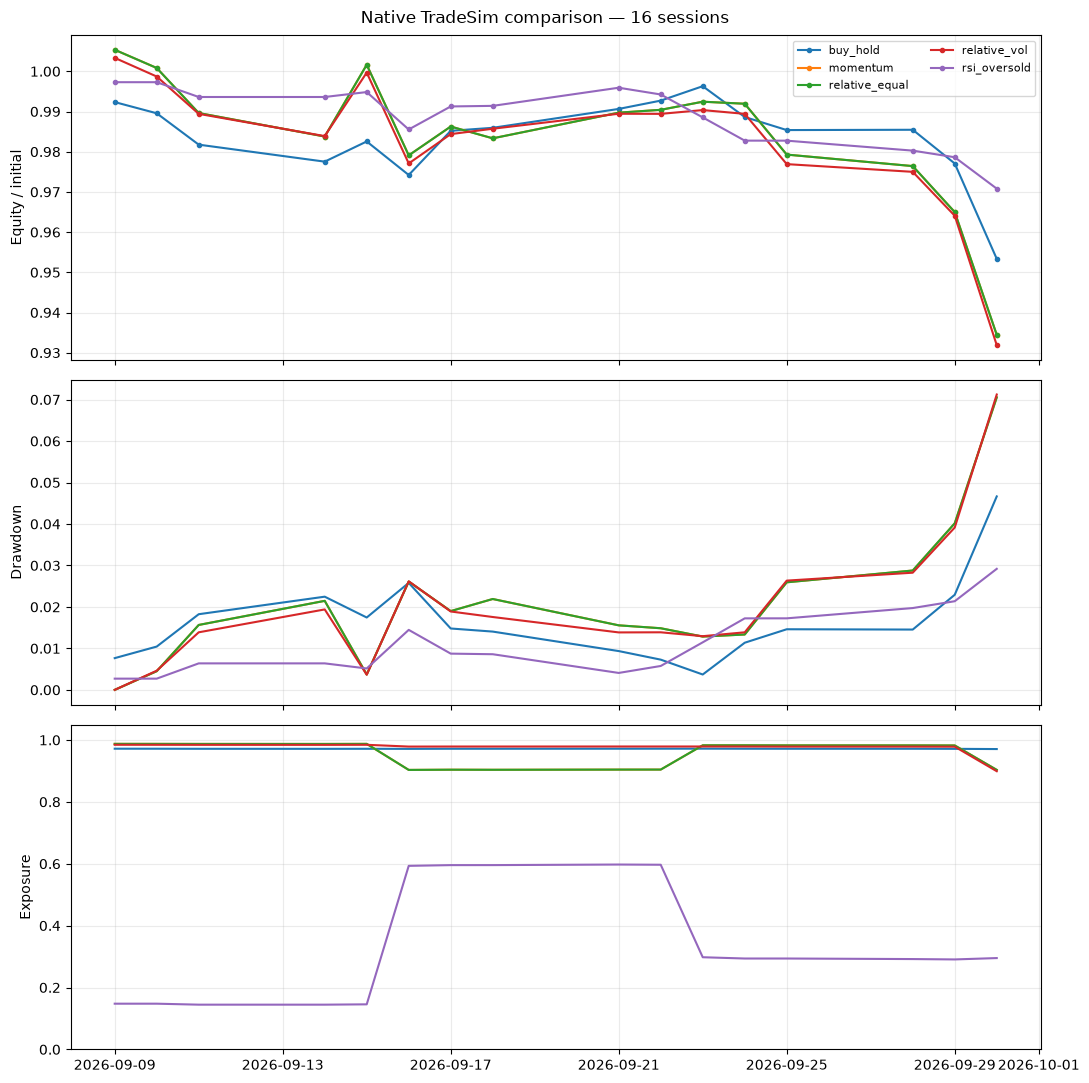

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
for name, group in equity.groupby("strategy", sort=False):
    group = group.sort_values("date")
    axes[0].plot(group.date, group.equity / 10_000_000, marker=".", label=name)
    peak = group.equity.cummax().clip(lower=10_000_000)
    axes[1].plot(group.date, 1 - group.equity / peak, label=name)
    axes[2].plot(group.date, group.exposure, label=name)
axes[0].set_ylabel("Equity / initial")
axes[1].set_ylabel("Drawdown")
axes[2].set_ylabel("Exposure")
axes[2].set_ylim(0, 1.05)
for ax in axes: ax.grid(alpha=.25)
axes[0].legend(ncol=2, fontsize=8)
fig.suptitle("Native TradeSim comparison — 16 sessions")
fig.tight_layout()
plt.show()

## Chronological 20-session daily research windows

The 24 evaluation windows were fixed chronologically after 11 development windows. They are non-overlapping. The daily adapter assumes feasible orders fill at the next session’s open with an adverse tick and costs; it does not model queue position, realistic liquidity, or partial fills. These results are research evidence, not official competition validation.

,strategy,windows,mean_return,median_return,worst_return,mean_excess,profitable_windows,outperform_windows
0,buy_hold,24,-0.19%,-0.68%,-6.31%,-1.03%,11,7
1,momentum,24,-0.86%,-1.35%,-9.21%,-1.71%,10,8
2,relative_equal,24,-0.86%,-1.35%,-9.21%,-1.71%,10,8
3,relative_vol,24,-1.30%,-1.52%,-9.10%,-2.14%,10,6
4,rsi_oversold,24,-1.35%,-0.70%,-8.86%,-2.20%,8,5


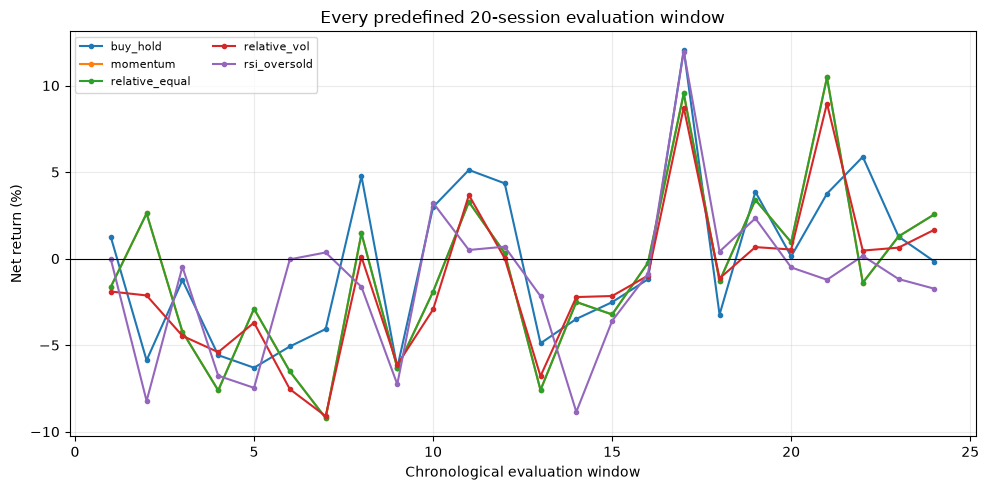

In [4]:
daily_summary = (evaluation.groupby("strategy", sort=False)
    .agg(windows=("net_return","size"), mean_return=("net_return","mean"),
         median_return=("net_return","median"), worst_return=("net_return","min"),
         mean_excess=("excess_return","mean"), profitable_windows=("net_return",lambda x: int((x>=0).sum())),
         outperform_windows=("excess_return",lambda x: int((x>=0).sum())))
    .reset_index())
display(daily_summary.style.format({"mean_return":"{:.2%}","median_return":"{:.2%}",
    "worst_return":"{:.2%}","mean_excess":"{:.2%}"}))
fig, ax = plt.subplots(figsize=(10, 5))
for name, group in evaluation.groupby("strategy", sort=False):
    ax.plot(range(1,len(group)+1), group.net_return*100, marker="o", ms=3, label=name)
ax.axhline(0,color="black",lw=.8)
ax.set(xlabel="Chronological evaluation window",ylabel="Net return (%)",title="Every predefined 20-session evaluation window")
ax.grid(alpha=.25); ax.legend(ncol=2,fontsize=8); fig.tight_layout(); plt.show()

## How to read the comparison

- Profitability asks whether portfolio return is positive. Benchmark outperformance asks whether excess return is positive. They are separate tests.
- Competition eligibility is not implied by a favorable return. The native run is shorter than 20 sessions and native order semantics differ from the stated IOC requirement; official eligibility is unverified.
- Buy-and-hold has no artificial round-trips, so it cannot meet the completed-trade requirement by construction.
- Momentum and relative strength have identical rankings when calculated on the same dates because subtracting the same SET50 return from every stock preserves rank. Comparing inverse-volatility with equal weights helps isolate sizing.
- RSI is a contrarian starting hypothesis, not a proven edge. The limited period and history do not establish statistical significance.